# Multimodal — Audio + Video (klasifikasi klip)
**Kapan dipakai:** tiap sampel adalah klip video bersuara (ekspresi + ucapan, wawancara,
kejadian dengan bunyi) dengan satu label per klip.

**Idenya:** suara diubah jadi embedding oleh wav2vec2, beberapa frame wajah diubah jadi
embedding oleh ResNet18. Keduanya pretrained dan tidak dilatih ulang. Dua embedding
disambung jadi satu baris ("early fusion"), lalu model sklearn biasa.

**Langkah:**
1. Baca daftar klip, ambil label dan aktor dari nama file.
2. Embedding audio dan video tiap klip, sambung.
3. Split per aktor, latih model, buat submission untuk klip test.

**Data demo:** CREMA-D mini (288 klip, 24 aktor, 6 emosi, lisensi ODbL). Aktor yang sama
tidak boleh ada di latih dan test sekaligus.

In [1]:
import cv2
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.nn import functional
from torchvision import models
from transformers import AutoFeatureExtractor, Wav2Vec2Model

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/multimodal/cremad_mini"   # GANTI saat lomba
CLIPS_CSV = f"{DATA_FOLDER}/daftar.csv"
AUDIO_FOLDER = f"{DATA_FOLDER}/audio"
VIDEO_FOLDER = f"{DATA_FOLDER}/video"
AUDIO_EXTENSION = ".wav"
VIDEO_EXTENSION = ".flv"
PRETRAINED = "../../pretrained"

NAME_COL = "nama"         # nama file tanpa ekstensi, misal 1001_IEO_HAP_LO
SAMPLE_RATE = 16000
N_FRAMES = 8              # frame diambil merata dari awal sampai akhir klip
FACE_TOP = 40             # kotak wajah (piksel): atas, bawah, kiri, kanan
FACE_BOTTOM = 300
FACE_LEFT = 110
FACE_RIGHT = 370
IMAGE_SIZE = 224
TEST_FRACTION = 0.25      # porsi aktor untuk test
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406])
MEAN = MEAN.view(1, 3, 1, 1).to(DEVICE)    # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225])
STD = STD.view(1, 3, 1, 1).to(DEVICE)

## Baca daftar klip
Nama file `1001_IEO_HAP_LO`: 4 huruf pertama = aktor, huruf ke-10 sampai 12 = emosi.

In [3]:
clips = pd.read_csv(CLIPS_CSV)
clips["actor"] = clips[NAME_COL].str[:4]
clips["label"] = clips[NAME_COL].str[9:12]
print(clips.shape)
print(clips["label"].value_counts())
clips.head()

(288, 3)
label
NEU    48
HAP    48
SAD    48
ANG    48
FEA    48
DIS    48
Name: count, dtype: int64


,nama,actor,label
0,1001_IEO_NEU_XX,1001,NEU
1,1001_IEO_HAP_LO,1001,HAP
2,1001_IEO_HAP_MD,1001,HAP
3,1001_IEO_SAD_LO,1001,SAD
4,1001_IEO_SAD_MD,1001,SAD


## Langkah 2a — embedding audio (wav2vec2)
Keluaran wav2vec2 dirata-rata sepanjang waktu = 768 angka per klip.

In [4]:
feature_extractor = AutoFeatureExtractor.from_pretrained(f"{PRETRAINED}/wav2vec2_base",
                                                         local_files_only=True)
encoder = Wav2Vec2Model.from_pretrained(f"{PRETRAINED}/wav2vec2_base", local_files_only=True)
encoder.eval()
encoder = encoder.to(DEVICE)


def audio_embedding(name):
    audio, _ = librosa.load(f"{AUDIO_FOLDER}/{name}{AUDIO_EXTENSION}", sr=SAMPLE_RATE)
    inputs = feature_extractor(audio, sampling_rate=SAMPLE_RATE, return_tensors="pt")
    with torch.no_grad():
        output = encoder(inputs.input_values.to(DEVICE))
    mean_over_time = output.last_hidden_state.mean(dim=1)
    return mean_over_time[0].cpu().numpy()


# coba pada klip pertama
print(audio_embedding(clips[NAME_COL][0]).shape)

audio_rows = []
for name in clips[NAME_COL]:
    audio_rows.append(audio_embedding(name))
audio_features = np.stack(audio_rows)
print("embedding audio:", audio_features.shape)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: ../../pretrained/wav2vec2_base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(768,)


embedding audio: (288, 768)


## Langkah 2b — embedding video (ResNet18 pada frame wajah)
`N_FRAMES` frame diambil merata, dipotong ke kotak wajah, embedding tiap frame dirata-rata.

In [5]:
backbone = models.resnet18(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()                  # keluaran = 512 angka per frame
backbone = backbone.to(DEVICE)
backbone.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [6]:
def video_embedding(name):
    video = cv2.VideoCapture(f"{VIDEO_FOLDER}/{name}{VIDEO_EXTENSION}")
    frames = []
    ok, frame = video.read()
    while ok:
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ok, frame = video.read()
    positions = np.linspace(0, len(frames) - 1, N_FRAMES)
    positions = positions.round().astype(int)
    faces = np.stack(frames)[positions][:, FACE_TOP:FACE_BOTTOM, FACE_LEFT:FACE_RIGHT]
    batch = torch.tensor(faces).permute(0, 3, 1, 2)
    batch = batch.float().to(DEVICE) / 255
    batch = functional.interpolate(batch, size=IMAGE_SIZE, mode="bilinear")
    with torch.no_grad():
        per_frame = backbone((batch - MEAN) / STD).cpu().numpy()
    return per_frame.mean(axis=0)


# coba pada klip pertama
print(video_embedding(clips[NAME_COL][0]).shape)

video_rows = []
for name in clips[NAME_COL]:
    video_rows.append(video_embedding(name))
video_features = np.stack(video_rows)
print("embedding video:", video_features.shape)

(512,)


embedding video: (288, 512)


## Pilih feature (satu baris aktif)
Coba ketiganya untuk melihat modalitas mana yang membantu (bahan presentasi).

In [7]:
X = np.hstack([audio_features, video_features])     # gabungan
# X = audio_features                                # audio saja
# X = video_features                                # video saja
y = clips["label"]
groups = clips["actor"]
print("feature:", X.shape)

feature: (288, 1280)


## Langkah 3a — split per aktor

In [8]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=SEED)
train_rows, test_rows = next(splitter.split(X, y, groups=groups))
print("klip latih:", len(train_rows), "| klip test:", len(test_rows))

klip latih: 216 | klip test: 72


## Langkah 3b — model + evaluasi GroupKFold di data latih
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [9]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=3000))
# model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=8, verbose=-1)

oof_predictions = cross_val_predict(model, X[train_rows], y.iloc[train_rows],
                                    cv=GroupKFold(5), groups=groups.iloc[train_rows])
cv_f1 = f1_score(y.iloc[train_rows], oof_predictions, average="macro")
print("F1 macro GroupKFold:", round(cv_f1, 4))

F1 macro GroupKFold: 0.5525


## Submission (klip test)

In [10]:
model.fit(X[train_rows], y.iloc[train_rows])
predictions = model.predict(X[test_rows])

submission = pd.DataFrame()
submission["nama"] = clips[NAME_COL].iloc[test_rows].to_numpy()
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,nama,label
0,1001_IEO_NEU_XX,DIS
1,1001_IEO_HAP_LO,HAP
2,1001_IEO_HAP_MD,DIS
3,1001_IEO_SAD_LO,SAD
4,1001_IEO_SAD_MD,DIS


## Cek dengan kunci jawaban (HAPUS saat lomba)
Di data demo label klip test diketahui dari nama file.

F1 macro test: 0.5619


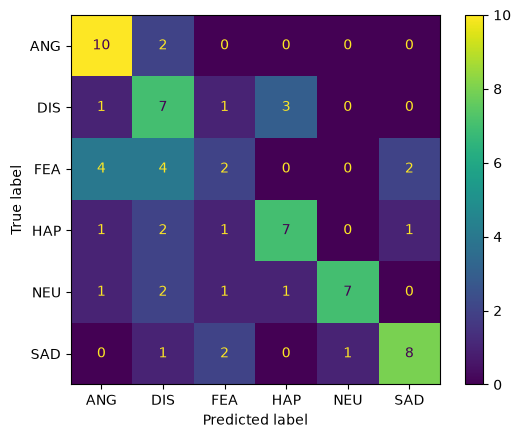

In [11]:
test_truth = y.iloc[test_rows]
print("F1 macro test:", round(f1_score(test_truth, predictions, average="macro"), 4))
ConfusionMatrixDisplay.from_predictions(test_truth, predictions)
plt.show()